# V3 — Tối ưu crop trên nền V2

## 1. Clone repository và kiểm tra môi trường

Bật **Runtime → Change runtime type → GPU**. `REPO_URL` giống notebook V1. `BRANCH` mặc định là `v3`. Dùng nhánh đã có code crop với stack gộp hoặc dùng checkout được upload. Tên branch không quyết định version pipeline.

Repo được clone vào `/content/panorama-stitching-project`. Với checkout có sẵn và sạch, `UPDATE_REPO=True` sẽ fetch/checkout/pull nhánh đã chọn. Nếu có thay đổi local, cell giữ chúng và bỏ qua cập nhật. Đặt `UPDATE_REPO=False` để dùng project đã upload/giải nén. Dataset cần có trước cell benchmark.

Giữ cùng GPU/session, tham số và build cho mọi phép so sánh. Mỗi lần chạy lưu vào thư mục report riêng.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import json
import os
import re
import shlex
import shutil
import subprocess
from statistics import geometric_mean
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_URL = 'https://github.com/nganbee/panorama-stitching-project.git'
BRANCH = 'v3'  # Set this to the branch containing the updated V3 sources.
REPO_DIR = Path('/content/panorama-stitching-project')
UPDATE_REPO = True  # False: use existing/uploaded code without fetching or switching branches.

def run(args, check=True, log=None):
    args = [str(arg) for arg in args]
    command = shlex.join(args)
    print('$', command, flush=True)
    result = subprocess.run(args, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(result.stdout, flush=True)
    if log is not None:
        Path(log).write_text('$ ' + command + '\n' + result.stdout, encoding='utf-8')
    if check:
        result.check_returncode()
    return result

if not REPO_DIR.exists():
    run(['git', 'clone', '--branch', BRANCH, REPO_URL, REPO_DIR])
elif UPDATE_REPO and (REPO_DIR / '.git').exists():
    local_changes = run(['git', '-C', REPO_DIR, 'status', '--porcelain']).stdout.strip()
    if local_changes:
        print('Using existing local changes; fetch/checkout/pull skipped.')
    else:
        run(['git', '-C', REPO_DIR, 'fetch', 'origin', BRANCH])
        run(['git', '-C', REPO_DIR, 'checkout', BRANCH])
        run(['git', '-C', REPO_DIR, 'pull', '--ff-only', 'origin', BRANCH])
else:
    print('Using existing/uploaded project:', REPO_DIR)

required_sources = ['src/stage_implementations/v2_stage4.cu', 'src/cuda/v2_pipeline.cu',
                    'src/stage_implementations/v3_stage6.cu', 'src/cuda/v3_pipeline.cu',
                    'src/tools/v3/test_v3_stage6.cu', 'src/tools/v3/stage6_reference.cu',
                    'src/tools/v3/test_v3_pipeline.cpp', 'src/tools/v2/test_matching.cpp']
missing_sources = [name for name in required_sources if not (REPO_DIR / name).is_file()]
assert not missing_sources, ('Missing cumulative V3 sources: ' + ', '.join(missing_sources) +
                             '. Use the branch or uploaded checkout containing V2 and V3.')
os.chdir(REPO_DIR)
GIT_BRANCH = GIT_COMMIT = None
if (REPO_DIR / '.git').exists():
    GIT_BRANCH = run(['git', 'branch', '--show-current']).stdout.strip()
    GIT_COMMIT = run(['git', 'rev-parse', 'HEAD']).stdout.strip()
print('Working directory:', Path.cwd())
RUNS = 5
RUN_SANITIZER = True
assert RUNS >= 5
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
REPORT_DIR = Path('reports/v3_experiment') / RUN_ID
OUT_DIR = Path('out/v3_experiment') / RUN_ID
for directory in [Path('build'), REPORT_DIR, OUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

assert shutil.which('nvcc'), 'CUDA toolkit required; select a Colab GPU runtime.'
run(['nvidia-smi'], log=REPORT_DIR / 'nvidia-smi.txt')
GPU = run(['nvidia-smi', '--query-gpu=name,uuid,driver_version', '--format=csv,noheader']).stdout.strip()
CUDA = run(['nvcc', '--version']).stdout
CPU_COMPILER = run(['g++', '--version']).stdout
ENVIRONMENT = {'gpu': GPU, 'cuda': CUDA, 'g++': CPU_COMPILER, 'runs': RUNS, 'warmup_runs': 1,
               'baseline': 'V2', 'candidate': 'V2 with shared warp and a compressed crop stack',
               'run_id': RUN_ID, 'repo_url': REPO_URL, 'requested_branch': BRANCH,
               'actual_branch': GIT_BRANCH, 'git_commit': GIT_COMMIT}
(REPORT_DIR / 'environment.json').write_text(json.dumps(ENVIRONMENT, indent=2), encoding='utf-8')
print('Reports:', REPORT_DIR)

$ git clone --branch v3 https://github.com/nganbee/panorama-stitching-project.git /content/panorama-stitching-project
Cloning into '/content/panorama-stitching-project'...

$ git branch --show-current
v3

$ git rev-parse HEAD
6ead536a05e6e2f9d24fd8281f65ac7a4c52a0ac

Working directory: /content/panorama-stitching-project
$ nvidia-smi
Sun Nov 22 11:46:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+============

## 2. Build V0–V3

V2 kế thừa V1 và thay S4 bằng descriptor tiling trong shared memory. V3 tiếp tục dùng S4 của V2. Cả bốn phiên bản chạy từ cùng CLI với cùng tham số.

In [2]:
INCLUDES = ['-Isrc/core_headers', '-Isrc/libraries']
CUDA_FLAGS = ['-O2', '-std=c++17', '--fmad=false', '-DPANORAMA_WITH_CUDA']
V3_FLAGS = CUDA_FLAGS + ['-DPANORAMA_WITH_V2', '-DPANORAMA_WITH_V3']
V0_COMMON = ['src/integration/v0_pipeline.cpp',
             'src/stage_implementations/v0_stage12.cpp', 'src/stage_implementations/v0_stage34.cpp',
             'src/stage_implementations/v0_stage5.cpp', 'src/stage_implementations/v0_stage6.cpp']
V1_SOURCES = V0_COMMON + ['src/stage_implementations/v1_stage12.cu',
             'src/stage_implementations/v1_stage34.cu', 'src/stage_implementations/v1_stage5.cu',
             'src/stage_implementations/v1_stage6.cu', 'src/cuda/cuda_pipeline.cu',
             'src/libraries/stb_impl.cpp']
V2_SOURCES = V1_SOURCES + ['src/cuda/v2_pipeline.cu', 'src/stage_implementations/v2_stage4.cu']
V3_SOURCES = V2_SOURCES + ['src/cuda/v3_pipeline.cu', 'src/stage_implementations/v3_stage6.cu']
S6_SOURCES = ['src/stage_implementations/v0_stage6.cpp',
              'src/stage_implementations/v1_stage6.cu', 'src/stage_implementations/v3_stage6.cu']
BINARY = 'build/stitch_v3'
VERSIONS = [0, 1, 2, 3]
run(['nvcc', *V3_FLAGS, *INCLUDES, 'src/integration/main.cpp', *V3_SOURCES, '-o', BINARY])
run(['nvcc', *V3_FLAGS, *INCLUDES, 'src/tools/v2/test_matching.cpp',
     'src/stage_implementations/v0_stage34.cpp', 'src/stage_implementations/v1_stage34.cu',
     'src/stage_implementations/v2_stage4.cu', '-o', 'build/stage34_v2_selftest'])
run(['nvcc', *V3_FLAGS, *INCLUDES, 'src/tools/v3/test_v3_stage6.cu',
     'src/tools/v3/stage6_reference.cu', *S6_SOURCES, '-o', 'build/test_v3_stage6'])
run(['nvcc', *V3_FLAGS, *INCLUDES, 'src/tools/v3/test_v3_pipeline.cpp', *V3_SOURCES,
     '-o', 'build/test_v3_pipeline'])
print('GPU:', GPU)
versions = run([BINARY, '--list-versions']).stdout.split()
assert versions == list(map(str, VERSIONS)), versions
parameters = json.loads(run([BINARY, '--dump-params']).stdout)
assert parameters['available_versions'] == VERSIONS
(REPORT_DIR / 'parameters.json').write_text(json.dumps(parameters, indent=2), encoding='utf-8')
ENVIRONMENT['build_flags'] = V3_FLAGS
ENVIRONMENT['sources'] = V3_SOURCES
ENVIRONMENT['binary'] = BINARY
(REPORT_DIR / 'environment.json').write_text(json.dumps(ENVIRONMENT, indent=2), encoding='utf-8')


$ nvcc -O2 -std=c++17 --fmad=false -DPANORAMA_WITH_CUDA -DPANORAMA_WITH_V2 -DPANORAMA_WITH_V3 -Isrc/core_headers -Isrc/libraries src/integration/main.cpp src/integration/v0_pipeline.cpp src/stage_implementations/v0_stage12.cpp src/stage_implementations/v0_stage34.cpp src/stage_implementations/v0_stage5.cpp src/stage_implementations/v0_stage6.cpp src/stage_implementations/v1_stage12.cu src/stage_implementations/v1_stage34.cu src/stage_implementations/v1_stage5.cu src/stage_implementations/v1_stage6.cu src/cuda/cuda_pipeline.cu src/libraries/stb_impl.cpp src/cuda/v2_pipeline.cu src/stage_implementations/v2_stage4.cu src/cuda/v3_pipeline.cu src/stage_implementations/v3_stage6.cu -o build/stitch_v3

$ nvcc -O2 -std=c++17 --fmad=false -DPANORAMA_WITH_CUDA -DPANORAMA_WITH_V2 -DPANORAMA_WITH_V3 -Isrc/core_headers -Isrc/libraries tools/v2/test_matching.cpp src/stage_implementations/v0_stage34.cpp src/stage_implementations/v1_stage34.cu src/stage_implementations/v2_stage4.cu -o build/stage34_v2

1753

## 3. Profile V2 để chọn điểm tối ưu

Chạy Nsight Systems trên V2 trước khi chạy V3. Mặc định lấy hai ca cùng cảnh ở 1080p và 4K. Báo thời gian warp, quét crop và tổng bốn kernel crop, cùng tỷ trọng crop trong thời gian kernel S6. Bảng ghi rõ phần nào tốn nhất theo trace thực tế.

In [3]:
PROFILE_CASES = [('location1', 'medium_1080p'), ('location1', 'large_4k')]
if not shutil.which('nsys'):
    raise RuntimeError('Nsight Systems (nsys) is required for the V2 baseline profile. Use a CUDA GPU runtime with nsys.')

def read_kernel_summary(output):
    rows = []
    columns = None
    for values in csv.reader(output.splitlines()):
        values = [value.strip().lstrip('\ufeff') for value in values]
        if {'Total Time (ns)', 'Instances', 'Name'} <= set(values):
            columns = values
        elif columns is not None and len(values) == len(columns):
            row = dict(zip(columns, values))
            if str(row['Instances']).replace(',', '').isdigit():
                rows.append({'name': row['Name'],
                             'total_ns': float(row['Total Time (ns)'].replace(',', '')),
                             'instances': int(row['Instances'].replace(',', ''))})
    if not rows:
        raise RuntimeError('No CUDA kernel rows in Nsight Systems CSV. See the saved nsys log.')
    return rows

def profile_s6(scene, resolution, version):
    case = scene + '_' + resolution
    left = Path('dataset') / scene / resolution / '1.jpg'
    right = left.with_name('2.jpg')
    if not (left.is_file() and right.is_file()):
        raise FileNotFoundError(f'Missing profile images: {left}, {right}')
    prefix = REPORT_DIR / f'nsys_v{version}_{case}'
    report = prefix.with_suffix('.nsys-rep')
    target = [BINARY, left, right, OUT_DIR / f'profile_v{version}_{case}.png',
              '--version', version, '--runs', RUNS]
    print(f'PROFILE GPU: {GPU} case: {case} version: {version}', flush=True)
    run(['nsys', 'profile', '--trace=cuda', '--sample=none', '--force-overwrite=true',
         '-o', prefix, *target], log=prefix.with_suffix('.log'))
    if not report.is_file():
        raise RuntimeError(f'Nsight Systems did not produce {report}')
    stats = run(['nsys', 'stats', '--report', 'cuda_gpu_kern_sum', '--format', 'csv',
                 '--output', '-', report], log=prefix.with_name(prefix.name + '_stats.txt'))
    kernels = read_kernel_summary(stats.stdout)
    pd.DataFrame(kernels).to_csv(prefix.with_name(prefix.name + '_kernels.csv'), index=False)

    def matching(name):
        return [row for row in kernels if re.search(rf'\b{re.escape(name)}\b', row['name'])]

    if not matching('nearest_tiled_kernel'):
        raise RuntimeError(f'S4 V2 kernel missing from {report}')
    if matching('warp_blend_texture_kernel'):
        raise RuntimeError('Unexpected texture warp. Build the crop-only V3 checkout.')

    def per_run_ms(name):
        rows = matching(name)
        # This trace includes the CLI warm-up plus its timed iterations.
        if sum(row['instances'] for row in rows) != RUNS + 1:
            raise RuntimeError(f'Unexpected launch count for {name} in {report}')
        return sum(row['total_ns'] for row in rows) / (RUNS + 1) / 1e6

    scan = 'find_crop_rows_kernel' if version == 2 else 'find_crop_rows_compressed_stack_kernel'
    parts = {'canvas_ms': per_run_ms('prepare_canvas_kernel'),
             'warp_ms': per_run_ms('warp_blend_kernel'),
             'histogram_ms': per_run_ms('build_crop_histograms_kernel'),
             'crop_scan_ms': per_run_ms(scan),
             'crop_reduce_ms': per_run_ms('reduce_crop_rows_kernel'),
             'crop_copy_ms': per_run_ms('crop_image_kernel')}
    crop_ms = sum(parts[key] for key in ('histogram_ms', 'crop_scan_ms', 'crop_reduce_ms', 'crop_copy_ms'))
    s6_ms = sum(parts.values())
    return {'case': case, 'version': version, 'gpu': GPU, **parts,
            'crop_ms': crop_ms, 's6_kernels_ms': s6_ms,
            'crop_share_s6_pct': 100 * crop_ms / s6_ms,
            'scan_share_crop_pct': 100 * parts['crop_scan_ms'] / crop_ms}

baseline_profiles = [profile_s6(scene, resolution, 2) for scene, resolution in PROFILE_CASES]
pd.DataFrame(baseline_profiles).to_csv(REPORT_DIR / 'profile_v2_s6.csv', index=False)
display(pd.DataFrame(baseline_profiles).round(3))
for row in baseline_profiles:
    s6_parts = {'crop': row['crop_ms'], 'warp': row['warp_ms'], 'canvas': row['canvas_ms']}
    largest = max(s6_parts, key=s6_parts.get)
    print(f"{row['case']}: {largest} tốn nhất trong S6 của V2. "
          f"Crop chiếm {row['crop_share_s6_pct']:.1f}% thời gian kernel S6, "
          f"trong đó quét hàng chiếm {row['scan_share_crop_pct']:.1f}% thời gian crop.")

PROFILE GPU: Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224da1d7, 580.82.07 case: location1_medium_1080p version: 2
$ nsys profile --trace=cuda --sample=none --force-overwrite=true -o reports/v3_experiment/20261122T114605927358Z/nsys_v2_location1_medium_1080p build/stitch_v3 dataset/location1/medium_1080p/1.jpg dataset/location1/medium_1080p/2.jpg out/v3_experiment/20261122T114605927358Z/profile_v2_location1_medium_1080p.png --version 2 --runs 5
version=2 runs=5 imageA=1920x1080 imageB=1920x1080
keypoints_A=1956 keypoints_B=2283 matches=973 inliers=689
panorama=4444x1080 inlier_ratio=0.708
avg_ms gray=0.178 blur=0.536 harris=1.359 nms_topk=0.801 describe=0.290 match=0.597 ransac=13.498 warp_blend=26.708 h2d=22.401 d2h=15.550 kernel_total=43.968 end_to_end=121.678
Generating '/tmp/nsys-report-04f4.qdstrm'

[1/1] [0%                          ] nsys_v2_location1_medium_1080p.nsys-rep
[1/1] [0%                          ] nsys_v2_location1_medium_1080p.nsys-rep
[1/1] [5%                     

,case,version,gpu,canvas_ms,warp_ms,histogram_ms,crop_scan_ms,crop_reduce_ms,crop_copy_ms,crop_ms,s6_kernels_ms,crop_share_s6_pct,scan_share_crop_pct
0,location1_medium_1080p,2,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.016,17.466,0.389,12.293,0.009,0.209,12.900,30.382,42.459,95.298
1,location1_large_4k,2,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.013,54.770,2.381,30.603,0.012,0.758,33.754,88.537,38.125,90.665


location1_medium_1080p: warp tốn nhất trong S6 của V2. Crop chiếm 42.5% thời gian kernel S6, trong đó quét hàng chiếm 95.3% thời gian crop.
location1_large_4k: warp tốn nhất trong S6 của V2. Crop chiếm 38.1% thời gian kernel S6, trong đó quét hàng chiếm 90.7% thời gian crop.


## 4. Ý tưởng tối ưu V3

Đọc bảng V2 ở trên để đánh giá crop có phải điểm tốn thời gian trong S6 và bước quét hàng chiếm bao nhiêu trong crop. Warp có thể là phần lớn nhất ở một số ca. V3 tập trung giảm công việc trong quét crop để phép so sánh đo được một thay đổi.

V3 giữ pipeline V2, gồm S4 descriptor tiling và đúng kernel `warp_blend_kernel` của V2. Trong kernel quét crop, các cột cùng chiều cao đang hoạt động dùng chung một mục `(height, left)`. Cột chiều cao 0 không vào stack. Mục trên cùng nằm trong biến cục bộ để giảm tra cứu. Cách duyệt và quy tắc chọn vùng đảm bảo cùng tọa độ crop và RGB.

## 5. Kiểm tra đầu ra trước khi đo

Test S4 đối chiếu kết quả matching của V2 với V0/V1. Test S6 cho hai cách quét cùng một mask và kiểm tra tọa độ crop, sau đó so từng byte RGB của panorama. Test toàn pipeline chạy V0–V3, đối chiếu với V0 và yêu cầu V2/V3 có cùng homography và panorama.

In [4]:
run([BINARY, '--selftest', '--version', '1'], log=REPORT_DIR / 'smoke_v1.txt')
run(['build/stage34_v2_selftest'], log=REPORT_DIR / 'stage4_v2_correctness.txt')
run([BINARY, '--selftest', '--version', '3'], log=REPORT_DIR / 'smoke_v3.txt')
stage6_check = run(['build/test_v3_stage6'], log=REPORT_DIR / 'stage6_correctness.txt')
assert 'PASS: V3 S6 shared warp and compressed crop stack verification' in stage6_check.stdout, (
    'Use the checkout containing the compressed crop stack implementation and tests.')
run(['build/test_v3_pipeline'], log=REPORT_DIR / 'pipeline_synthetic.txt')
if RUN_SANITIZER and shutil.which('compute-sanitizer'):
    run(['compute-sanitizer', '--tool', 'memcheck', '--error-exitcode', '1', 'build/test_v3_stage6'],
        log=REPORT_DIR / 'sanitizer_memcheck.txt')
else:
    print('Compute Sanitizer not run; not counted as a memory-check PASS.')

$ build/stitch_v3 --selftest --version 1
V1 CUDA S1-S2 smoke selftest PASS (keypoints=43)

$ build/stage34_v2_selftest
PASS: S4 V0/V1/V2 ordered matching, tiles, ratio and cross-check

$ build/stitch_v3 --selftest --version 3
V3 CUDA S6 smoke selftest PASS

$ build/test_v3_stage6
PASS: identity random RGB; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000000
PASS: integer translation; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000000
PASS: negative translation; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000000
PASS: fractional translation / manual bilinear; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000000
PASS: perspective / feather / partial blocks; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000000
PASS: single pixel; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000000
PASS: single column; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000000
PASS: single row; crop coordinates and RGB exact vs V1; V0 RGB MAE=0.000000

## 6. Benchmark V0–V3 trên 12 cặp ảnh

Đo cả bốn phiên bản trên 4 cảnh × 3 độ phân giải. Đảo thứ tự V2/V3 theo cảnh, làm nóng một lần rồi lấy trung bình ít nhất năm lượt. E2E là thời gian thực của pipeline, gồm cấp phát, gọi kernel, đồng bộ và copy. I/O ảnh nằm ngoài khoảng đo. Các lượt benchmark chạy riêng với Nsight Systems.

In [5]:
SCENES = ['location1', 'location2', 'location3', 'challenge']
RESOLUTIONS = ['small_720p', 'medium_1080p', 'large_4k']
CASES = [(scene, resolution, Path('dataset') / scene / resolution / '1.jpg',
          Path('dataset') / scene / resolution / '2.jpg')
         for scene in SCENES for resolution in RESOLUTIONS]
missing = [str(path) for _, _, left, right in CASES for path in [left, right] if not path.is_file()]
assert not missing, 'Missing dataset inputs: ' + ', '.join(missing)
records = []
for case_index, (scene, resolution, left, right) in enumerate(CASES):
    case = scene + '_' + resolution
    print('\nCASE:', case, 'GPU:', GPU, flush=True)
    verification = run(['build/test_v3_pipeline', left, right], check=False,
                       log=REPORT_DIR / (case + '_correctness.txt'))
    parity = 'PASS' if verification.returncode == 0 else 'FAILED/UNVERIFIED'
    versions = VERSIONS if (case_index // len(RESOLUTIONS)) % 2 == 0 else [0, 1, 3, 2]
    for version in versions:
        print('GPU:', GPU, 'case:', case, 'version:', version, flush=True)
        report = REPORT_DIR / (case + '_v' + str(version) + '.json')
        output = OUT_DIR / (case + '_v' + str(version) + '.png')
        result = run([BINARY, left, right, output, '--version', version, '--runs', RUNS, '--json', report],
                     check=False, log=REPORT_DIR / (case + '_v' + str(version) + '.txt'))
        metrics = json.loads(report.read_text(encoding='utf-8')) if report.is_file() else {}
        row = {'case': case, 'scene': scene, 'resolution': resolution, 'version': version,
               'gpu': GPU, 'baseline': 'V2', 'parity': parity,
               'status': 'ok' if result.returncode == 0 and metrics.get('status') == 'ok' else 'failed',
               'exit_code': result.returncode, 'report': str(report)}
        row.update(metrics.get('timings_ms', {}))
        for stage, value in metrics.get('stage_timings_ms', {}).items():
            row['stage_' + stage] = value
        records.append(row)
    pd.DataFrame(records).to_csv(REPORT_DIR / 'timings.csv', index=False)
results = pd.DataFrame(records)
display(results)
print('Verified panorama pairs:', results.loc[results.parity.eq('PASS'), 'case'].nunique(), '/', len(CASES))
print('Full 12-case run:', len(CASES) == 12)
display(results.loc[results.status.ne('ok') | results.parity.ne('PASS')])



CASE: location1_small_720p GPU: Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224da1d7, 580.82.07
$ build/test_v3_pipeline dataset/location1/small_720p/1.jpg dataset/location1/small_720p/2.jpg
  V0/V1 panorama MAE=0.000000000
  V0/V3 panorama MAE=0.000000000
  V2/V3 panorama MAE=0.000000000
PASS: V3 pipeline vs V0/V1/V2 (1280x720 + 1280x720, matches=620 inliers=448)

GPU: Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224da1d7, 580.82.07 case: location1_small_720p version: 0
$ build/stitch_v3 dataset/location1/small_720p/1.jpg dataset/location1/small_720p/2.jpg out/v3_experiment/20261122T114605927358Z/location1_small_720p_v0.png --version 0 --runs 5 --json reports/v3_experiment/20261122T114605927358Z/location1_small_720p_v0.json
version=0 runs=5 imageA=1280x720 imageB=1280x720
keypoints_A=1311 keypoints_B=1474 matches=620 inliers=448
panorama=2909x720 inlier_ratio=0.723
avg_ms gray=4.705 blur=68.129 harris=95.357 nms_topk=6.580 describe=10.272 match=775.072 ransac=18.806 warp_blend=310.971 h2d

,case,scene,resolution,version,gpu,baseline,parity,status,exit_code,report,...,h2d,d2h,kernel_total,end_to_end,stage_S1,stage_S2,stage_S3,stage_S4,stage_S5,stage_S6
0,location1_small_720p,location1,small_720p,0,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,0.000000,0.000000,0.000000,1289.895461,72.834243,101.937346,10.271591,775.072044,18.806269,310.970527
1,location1_small_720p,location1,small_720p,1,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,9.735667,6.910733,25.827488,61.352242,0.300531,0.902643,0.235430,0.543347,10.595552,13.249984
2,location1_small_720p,location1,small_720p,2,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,9.726208,6.703181,20.927392,54.932320,0.255443,0.764954,0.201261,0.296173,8.223603,11.185958
3,location1_small_720p,location1,small_720p,3,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,9.586509,6.812006,16.221146,52.997406,0.255347,0.764205,0.206336,0.296749,8.268602,6.429907
4,location1_medium_1080p,location1,medium_1080p,0,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,0.000000,0.000000,0.000000,2833.581802,150.180435,210.517779,16.305663,1764.937465,22.593215,669.043226
5,location1_medium_1080p,location1,medium_1080p,1,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,21.447629,14.333466,40.685696,110.143082,0.596813,1.858387,0.281830,0.812608,13.273632,23.862426
6,location1_medium_1080p,location1,medium_1080p,2,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,21.859942,14.378918,34.404262,103.289083,0.500595,1.518400,0.234074,0.439590,10.403482,21.308122
7,location1_medium_1080p,location1,medium_1080p,3,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,21.698720,14.696102,27.104646,103.604933,0.499610,1.524691,0.234272,0.437203,10.378054,14.030816
8,location1_large_4k,location1,large_4k,0,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,0.000000,0.000000,0.000000,7724.396006,552.555370,814.988248,25.879561,3551.803047,33.273772,2745.892031
9,location1_large_4k,location1,large_4k,1,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",V2,PASS,ok,0,reports/v3_experiment/20261122T114605927358Z/l...,...,82.132013,55.869837,102.285094,394.046796,1.880723,5.418688,0.528640,0.896218,12.653734,80.907091


Verified panorama pairs: 12 / 12
Full 12-case run: True


,case,scene,resolution,version,gpu,baseline,parity,status,exit_code,report,...,h2d,d2h,kernel_total,end_to_end,stage_S1,stage_S2,stage_S3,stage_S4,stage_S5,stage_S6


## 7. So sánh S6 và thời gian toàn pipeline

Bảng chỉ tính ca PASS và cả bốn bản chạy thành công. S6 cộng thời gian kernel của stage 6. E2E đo thời gian toàn pipeline. V2 và V3 cùng sử dụng warp gốc, nên phép so sánh kiểm tra tác động của việc đổi kernel quét crop.

,case,resolution,GPU,S4 V1 (ms),S4 V2 (ms),S4 V3 (ms),S6 V2 (ms),S6 V3 (ms),S6 speedup V2/V3,E2E V0 (ms),...,E2E V2 (ms),E2E V3 (ms),E2E speedup V0/V1,E2E speedup V0/V2,E2E speedup V1/V2,E2E speedup V2/V3,E2E speedup V0/V3,V3 kernels (ms),V3 H2D (ms),V3 D2H (ms)
0,location1_small_720p,small_720p,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.543347,0.296173,0.296749,11.185958,6.429907,1.739676,1289.895461,...,54.932320,52.997406,21.024423,23.481540,1.116870,1.036510,24.338841,16.221146,9.586509,6.812006
1,location1_medium_1080p,medium_1080p,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.812608,0.439590,0.437203,21.308122,14.030816,1.518666,2833.581802,...,103.289083,103.604933,25.726371,27.433507,1.066357,0.996951,27.349873,27.104646,21.698720,14.696102
2,location1_large_4k,large_4k,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.896218,0.627418,0.636589,80.910425,57.732506,1.401471,7724.396006,...,407.193437,376.866827,19.602738,18.969844,0.967714,1.080470,20.496354,79.181831,83.942784,57.082886
3,location2_small_720p,small_720p,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.713043,0.373216,0.370125,12.896979,5.194688,2.482725,1826.160033,...,57.653907,48.426503,29.782053,31.674523,1.063544,1.190545,37.709930,13.889709,9.695827,6.564928
4,location2_medium_1080p,medium_1080p,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.927462,0.571085,0.567584,22.569645,10.618368,2.125529,4181.436042,...,99.643976,85.913028,38.988341,41.963762,1.076316,1.159824,48.670570,21.052787,21.297069,13.719904
5,location2_large_4k,large_4k,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.882470,0.602560,0.627507,63.731904,40.540916,1.572039,6940.644470,...,368.056948,344.145285,17.156002,18.857529,1.099180,1.069481,20.167774,56.679956,83.216582,54.121997
6,location3_small_720p,small_720p,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.104410,0.061427,0.063155,12.736083,5.760333,2.210998,433.880833,...,52.812710,48.329448,6.580747,8.215462,1.248409,1.092765,8.977567,11.926669,9.791488,6.517242
7,location3_medium_1080p,medium_1080p,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.206131,0.170573,0.123750,20.736032,11.155354,1.858841,757.611203,...,117.868000,92.050362,7.409019,6.427624,0.867541,1.280473,8.230399,18.283129,21.496717,14.201690
8,location3_large_4k,large_4k,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.523757,0.395494,0.393965,61.551718,45.970861,1.338929,4022.669113,...,364.614425,355.447362,10.994411,11.032666,1.003480,1.025790,11.317201,58.839769,82.971475,57.456359
9,challenge_small_720p,small_720p,"Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224d...",0.384659,0.194106,0.195059,10.560762,8.328122,1.268084,928.410291,...,56.169016,52.228034,14.552343,16.528869,1.135822,1.075457,17.776091,14.931117,9.569024,7.041536


,S6 speedup V2/V3,E2E speedup V2/V3,E2E speedup V0/V3
resolution,,,
small_720p,1.865,1.097,19.563
medium_1080p,1.658,1.092,20.616
large_4k,1.355,1.034,17.479
all,1.612,1.074,19.174


S6 speedup V2/V3: V3 nhanh hơn ở 12/12 ca.
E2E speedup V2/V3: V3 nhanh hơn ở 9/12 ca.


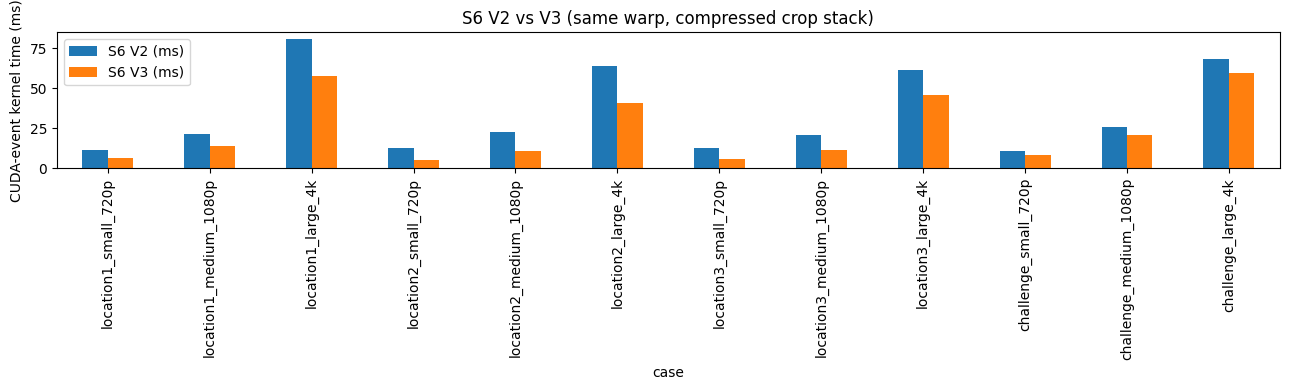

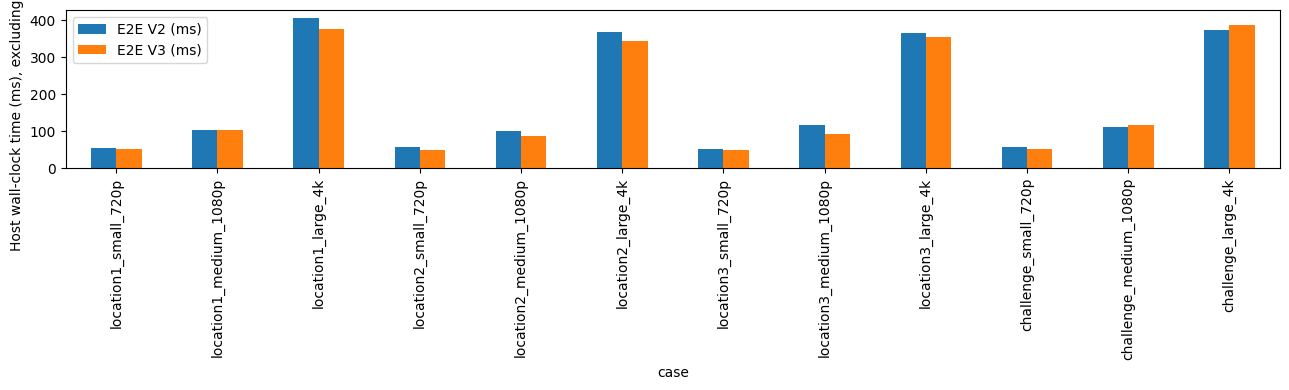

In [6]:
summary_rows = []
for case, group in results.groupby('case', sort=False):
    by_version = {int(row['version']): row for _, row in group.iterrows()}
    if not all(v in by_version and by_version[v]['status'] == 'ok' and by_version[v]['parity'] == 'PASS'
               for v in VERSIONS):
        continue
    v0, v1, v2, v3 = [by_version[v] for v in VERSIONS]
    summary_rows.append({'case': case, 'resolution': v3['resolution'], 'GPU': GPU,
        'S4 V1 (ms)': v1['match'], 'S4 V2 (ms)': v2['match'], 'S4 V3 (ms)': v3['match'],
        'S6 V2 (ms)': v2['warp_blend'], 'S6 V3 (ms)': v3['warp_blend'],
        'S6 speedup V2/V3': v2['warp_blend'] / v3['warp_blend'],
        'E2E V0 (ms)': v0['end_to_end'], 'E2E V1 (ms)': v1['end_to_end'],
        'E2E V2 (ms)': v2['end_to_end'], 'E2E V3 (ms)': v3['end_to_end'],
        'E2E speedup V0/V1': v0['end_to_end'] / v1['end_to_end'],
        'E2E speedup V0/V2': v0['end_to_end'] / v2['end_to_end'],
        'E2E speedup V1/V2': v1['end_to_end'] / v2['end_to_end'],
        'E2E speedup V2/V3': v2['end_to_end'] / v3['end_to_end'],
        'E2E speedup V0/V3': v0['end_to_end'] / v3['end_to_end'],
        'V3 kernels (ms)': v3['kernel_total'], 'V3 H2D (ms)': v3['h2d'], 'V3 D2H (ms)': v3['d2h']})
summary = pd.DataFrame(summary_rows)
summary.to_csv(REPORT_DIR / 'comparison.csv', index=False)
display(summary)
if not summary.empty:
    speedup_columns = ['S6 speedup V2/V3', 'E2E speedup V2/V3', 'E2E speedup V0/V3']
    by_resolution = summary.groupby('resolution', sort=False)[speedup_columns].agg(geometric_mean)
    by_resolution.loc['all'] = summary[speedup_columns].agg(geometric_mean)
    by_resolution.to_csv(REPORT_DIR / 'comparison_by_resolution.csv')
    display(by_resolution.round(3))
    for name in speedup_columns[:2]:
        print(f"{name}: V3 nhanh hơn ở {(summary[name] > 1).sum()}/{len(summary)} ca.")
    ax = summary.set_index('case')[['S6 V2 (ms)', 'S6 V3 (ms)']].plot.bar(figsize=(13, 4))
    ax.set_ylabel('CUDA-event kernel time (ms)')
    ax.set_title('S6 V2 vs V3 (same warp, compressed crop stack)')
    plt.tight_layout()
    plt.show()
    ax = summary.set_index('case')[['E2E V2 (ms)', 'E2E V3 (ms)']].plot.bar(figsize=(13, 4))
    ax.set_ylabel('Host wall-clock time (ms), excluding image I/O')
    plt.tight_layout()
    plt.show()
else:
    print('No verified successful comparison; investigate logs. No speedup claim.')

## 8. Profile V3 và kiểm tra crop có nhanh hơn không

Profile V3 trên đúng các ca đã đo V2 và đã qua kiểm tra đầu ra. So riêng thời gian quét hàng, tổng bốn kernel crop và warp. S6 và E2E trong bảng dưới được lấy từ lượt benchmark không bật profiler. Speedup lớn hơn 1 nghĩa là V3 nhanh hơn ở số đo đó.

In [7]:
verified = summary.set_index('case').to_dict('index') if not summary.empty else {}
profile_comparison = []
for (scene, resolution), v2 in zip(PROFILE_CASES, baseline_profiles):
    case = v2['case']
    if case not in verified:
        print(f'{case}: chưa xác nhận đầu ra, bỏ qua so sánh profiler V2/V3.')
        continue
    v3 = profile_s6(scene, resolution, 3)
    timing = verified[case]
    profile_comparison.append({'case': case,
        'warp_v2_ms': v2['warp_ms'], 'warp_v3_ms': v3['warp_ms'],
        'crop_scan_v2_ms': v2['crop_scan_ms'], 'crop_scan_v3_ms': v3['crop_scan_ms'],
        'crop_v2_ms': v2['crop_ms'], 'crop_v3_ms': v3['crop_ms'],
        'crop_scan_speedup': v2['crop_scan_ms'] / v3['crop_scan_ms'],
        'crop_speedup': v2['crop_ms'] / v3['crop_ms'],
        's6_speedup': timing['S6 speedup V2/V3'],
        'e2e_speedup': timing['E2E speedup V2/V3']})
    outcome = 'giảm' if v3['crop_ms'] < v2['crop_ms'] else 'tăng' if v3['crop_ms'] > v2['crop_ms'] else 'giữ nguyên'
    print(f"{case}: thời gian crop {outcome} ({v2['crop_ms']:.3f} → {v3['crop_ms']:.3f} ms).")
if profile_comparison:
    comparison = pd.DataFrame(profile_comparison)
    comparison.to_csv(REPORT_DIR / 'crop_profile_comparison.csv', index=False)
    display(comparison.round(3))
else:
    print('Không có ca profile V3 đã xác nhận để đối chiếu.')

PROFILE GPU: Tesla T4, GPU-ce7a7ef1-261b-f48a-afa7-ca88224da1d7, 580.82.07 case: location1_medium_1080p version: 3
$ nsys profile --trace=cuda --sample=none --force-overwrite=true -o reports/v3_experiment/20261122T114605927358Z/nsys_v3_location1_medium_1080p build/stitch_v3 dataset/location1/medium_1080p/1.jpg dataset/location1/medium_1080p/2.jpg out/v3_experiment/20261122T114605927358Z/profile_v3_location1_medium_1080p.png --version 3 --runs 5
version=3 runs=5 imageA=1920x1080 imageB=1920x1080
keypoints_A=1956 keypoints_B=2283 matches=973 inliers=689
panorama=4444x1080 inlier_ratio=0.708
avg_ms gray=0.163 blur=0.538 harris=1.422 nms_topk=0.753 describe=0.307 match=0.657 ransac=15.513 warp_blend=18.342 h2d=21.620 d2h=14.209 kernel_total=37.695 end_to_end=107.550
Generating '/tmp/nsys-report-218d.qdstrm'

[1/1] [0%                          ] nsys_v3_location1_medium_1080p.nsys-rep
[1/1] [0%                          ] nsys_v3_location1_medium_1080p.nsys-rep
[1/1] [7%                     

,case,warp_v2_ms,warp_v3_ms,crop_scan_v2_ms,crop_scan_v3_ms,crop_v2_ms,crop_v3_ms,crop_scan_speedup,crop_speedup,s6_speedup,e2e_speedup
0,location1_medium_1080p,17.466,17.858,12.293,2.391,12.900,2.990,5.142,4.314,1.519,0.997
1,location1_large_4k,54.770,57.802,30.603,5.634,33.754,8.847,5.432,3.815,1.401,1.080
